In [6]:
from __future__ import annotations

import json
import math
import random
import statistics
import time
from pathlib import Path

# ---------------------------------------------------------------------------
# Параметры эксперимента
# ---------------------------------------------------------------------------

#: Размеры массивов, для которых generate_data.py создаёт файлы.
SIZES = (1_000, 3_000, 10_000, 30_000, 100_000)

#: Для квадратичного алгоритма n = 100 000 исключён: это порядка 15 минут.
#: Размер 500 берётся как префикс файла на 1 000 элементов — так у нас
#: остаётся пять точек, как требует задание.
QUADRATIC_SIZES = (500, 1_000, 3_000, 10_000, 30_000)

#: Показатели степени для замера бинарного возведения в степень.
EXPONENTS = (10**3, 10**4, 10**5, 10**6, 10**7)

#: Модуль для возведения в степень. Без него Python считает длинную арифметику,
#: и замер покажет рост длины чисел, а не число итераций (см. отчёт).
POW_MOD = 1_000_000_007
POW_BASE = 3

REPEATS = 5           # повторов на точку (берётся медиана)
POW_CALLS = 20_000    # вызовов binary_pow на один замер: иначе время неизмеримо мало

In [7]:
# ---------------------------------------------------------------------------
# 1. Алгоритмы (реализуются вручную, без sum/max и встроенного pow)
# ---------------------------------------------------------------------------


def array_sum(a: list[int]) -> int:
    """Сумма элементов массива. Ожидаемая сложность: TODO (обосновать в отчёте)."""
    total = 0
    for x in a:
        total += x
    return total


def array_max(a: list[int]) -> int:
    """Максимум массива (массив непуст). Ожидаемая сложность: TODO."""
    current_max = a[0]
    for i in range(1, len(a)):
        if a[i] > current_max:
            current_max = a[i]
    return current_max


def count_equal_pairs(a: list[int]) -> int:
    """Число пар (i, j), i < j, таких что a[i] == a[j]. Ожидаемая сложность: TODO."""
    n = len(a)
    pairs = 0
    for i in range(n):
        for j in range(i + 1, n):
            if a[i] == a[j]:
                pairs += 1
    return pairs


def binary_pow(x: int, n: int, mod: int | None = None) -> int:
    """Бинарное возведение в степень, n >= 0. Ожидаемая сложность: TODO.

    При заданном mod все умножения выполняются по модулю (результат x**n % mod).
    """
    res = 1 if mod is None else 1 % mod
    base = x if mod is None else x % mod

    while n > 0:
        if n & 1:
            res *= base
            if mod is not None:
                res %= mod
        base *= base
        if mod is not None:
            base %= mod
        n >>= 1

    return res

In [8]:
# ---------------------------------------------------------------------------
# 2. Данные варианта: поиск каталога и загрузка
# ---------------------------------------------------------------------------

# Эмуляция __file__ для совместимости со средой Jupyter Notebook
__file__ = Path.cwd() / "lab01.ipynb"


def find_data_dir(explicit: Path | None) -> Path:
    """Каталог с данными варианта: --data, либо data/generated рядом с работой."""
    if explicit is not None:
        if not explicit.is_dir():
            raise SystemExit(f"Каталог не найден: {explicit}")
        return explicit
    candidates = []
    for base in (Path.cwd(), Path(__file__).resolve().parent):
        for parent in (base, *base.parents):
            candidates.append(parent / "data" / "generated")
    for path in candidates:
        if path.is_dir():
            return path
    raise SystemExit(
        "Не найден каталог data/generated с данными варианта.\n"
        "Сгенерируйте данные из корня репозитория курса:\n"
        "    python scripts/generate_data.py --variant N --only arrays\n"
        "или укажите каталог явно: --data <путь>")


def check_variant(data_dir: Path, variant: int) -> None:
    """Сверить номер варианта с паспортом данных (manifest.json)."""
    manifest_path = data_dir / "manifest.json"
    if not manifest_path.is_file():
        print(f"ВНИМАНИЕ: в {data_dir} нет manifest.json — "
              f"не могу проверить, что данные относятся к варианту {variant}.")
        return
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    actual = manifest.get("variant")
    if actual != variant:
        raise SystemExit(
            f"Данные в {data_dir} сгенерированы для варианта {actual}, "
            f"а работа запущена с --variant {variant}.\n"
            f"Перегенерируйте данные: "
            f"python scripts/generate_data.py --variant {variant} --only arrays")
    print(f"Данные варианта {variant} (seed={manifest.get('seed')}) из {data_dir}")


def load_array(data_dir: Path, kind: str, n: int, limit: int | None = None) -> list[int]:
    """Загрузить массив arrays_<kind>_<n>.txt; limit — взять только первые limit чисел."""
    path = data_dir / f"arrays_{kind}_{n}.txt"
    if not path.is_file():
        raise SystemExit(
            f"Не найден файл данных: {path}\n"
            f"Сгенерируйте его: python scripts/generate_data.py "
            f"--variant <ваш вариант> --only arrays")
    values = [int(line) for line in path.read_text(encoding="utf-8").split()]
    return values[:limit] if limit is not None else values

In [9]:
# ---------------------------------------------------------------------------
# 3. Репрезентативные тесты и инварианты (шаги 1–3 методики верификации)
# ---------------------------------------------------------------------------


def self_check() -> None:
    """Граничные и типовые случаи + сверка с эталоном (sum, max, pow)."""
    # Граничные случаи
    assert array_sum([]) == 0
    assert array_sum([7]) == 7
    assert array_max([3, 1, 2]) == 3
    assert count_equal_pairs([]) == 0
    assert count_equal_pairs([5, 5, 5]) == 3          # пары (0,1), (0,2), (1,2)
    assert binary_pow(2, 0) == 1
    assert binary_pow(2, 10) == 1024
    assert binary_pow(2, 10, mod=1000) == 24

    # Сверка с эталонными реализациями на случайных данных
    rng = random.Random(0)
    for _ in range(200):
        a = [rng.randint(-50, 50) for _ in range(rng.randint(1, 60))]
        assert array_sum(a) == sum(a)
        assert array_max(a) == max(a)
    for _ in range(200):
        x, n = rng.randint(2, 50), rng.randint(0, 64)
        assert binary_pow(x, n, mod=POW_MOD) == pow(x, n, POW_MOD)

    # Проверка инвариантов
    assert count_equal_pairs(list(range(50))) == 0
    k = 40
    assert count_equal_pairs([7] * k) == k * (k - 1) // 2

    p_base, pa, pb = 3, 11, 19
    left_part = (binary_pow(p_base, pa, mod=POW_MOD) * binary_pow(p_base, pb, mod=POW_MOD)) % POW_MOD
    right_part = binary_pow(p_base, pa + pb, mod=POW_MOD)
    assert left_part == right_part

    sample_seq = [1, -5, 10, 42, -99]
    assert array_sum([-v for v in sample_seq]) == -array_sum(sample_seq)

    print("self_check: OK")

In [10]:
VARIANT = 13

data_dir = find_data_dir(None)
check_variant(data_dir, VARIANT)
self_check()

Данные варианта 13 (seed=43) из /home/webfurre/projects/unik/siaod-labs/data/generated
self_check: OK


In [11]:
# ---------------------------------------------------------------------------
# 4. Бенчмарк (методика — docs/reproducibility.md)
# ---------------------------------------------------------------------------


def bench(call) -> float:
    """Медиана времени выполнения call() по REPEATS запускам, с прогревом."""
    call()  # прогрев — не учитывается
    times = []
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        call()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)


def log_log_slope(points: list[tuple[int, float]]) -> float:
    """Наклон прямой в осях (log n, log t) — оценка показателя степени."""
    xs = [math.log10(n) for n, _ in points]
    ys = [math.log10(t) for _, t in points]
    mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
    return (sum((x - mx) * (y - my) for x, y in zip(xs, ys))
            / sum((x - mx) ** 2 for x in xs))


def run_benchmarks(data_dir: Path) -> dict[str, list[tuple[int, float]]]:
    """Замеры на данных варианта. Возвращает {имя алгоритма: [(n, t), ...]}."""
    results: dict[str, list[tuple[int, float]]] = {}

    # Линейные алгоритмы — на случайных массивах всех размеров
    random_arrays = {n: load_array(data_dir, "random", n) for n in SIZES}
    for name, fn in (("array_sum", array_sum), ("array_max", array_max)):
        points = []
        print(f"\n{name}:")
        for n in SIZES:
            a = random_arrays[n]
            t = bench(lambda: fn(a))
            points.append((n, t))
            print(f"  n={n:>7}  t={t:.6f} c")
        results[name] = points

    # Квадратичный алгоритм — на массивах с дубликатами (иначе пар почти нет)
    print("\ncount_equal_pairs:")
    points = []
    for n in QUADRATIC_SIZES:
        file_n = n if n in SIZES else min(s for s in SIZES if s >= n)
        a = load_array(data_dir, "dups", file_n, limit=n)
        t = bench(lambda: count_equal_pairs(a))
        points.append((n, t))
        print(f"  n={n:>7}  t={t:.6f} c")
    results["count_equal_pairs"] = points

    # Логарифмический алгоритм: одна операция слишком быстра, замеряем пачку
    # вызовов и делим на их число. Считаем по модулю — см. POW_MOD.
    print(f"\nbinary_pow (по {POW_CALLS} вызовов на точку, по модулю {POW_MOD}):")
    points = []
    for e in EXPONENTS:
        def batch(e: int = e) -> None:
            for _ in range(POW_CALLS):
                binary_pow(POW_BASE, e, mod=POW_MOD)
        t = bench(batch) / POW_CALLS
        points.append((e, t))
        print(f"  n={e:>9}  log2(n)={math.log2(e):5.1f}  t={t:.9f} c")
    results["binary_pow"] = points

    return results

In [12]:
results = run_benchmarks(data_dir)

print("\nНаклон в осях log-log (оценка показателя степени):")
for name in ("array_sum", "array_max", "count_equal_pairs"):
    print(f"  {name:20s} {log_log_slope(results[name]):.3f}")


array_sum:
  n=   1000  t=0.000014 c
  n=   3000  t=0.000041 c
  n=  10000  t=0.000136 c
  n=  30000  t=0.000410 c
  n= 100000  t=0.001400 c

array_max:
  n=   1000  t=0.000016 c
  n=   3000  t=0.000050 c
  n=  10000  t=0.000166 c
  n=  30000  t=0.000526 c
  n= 100000  t=0.001747 c

count_equal_pairs:
  n=    500  t=0.002610 c
  n=   1000  t=0.011034 c
  n=   3000  t=0.100080 c
  n=  10000  t=1.084807 c
  n=  30000  t=10.924324 c

binary_pow (по 20000 вызовов на точку, по модулю 1000000007):
  n=     1000  log2(n)= 10.0  t=0.000001018 c
  n=    10000  log2(n)= 13.3  t=0.000001328 c
  n=   100000  log2(n)= 16.6  t=0.000001523 c
  n=  1000000  log2(n)= 19.9  t=0.000002025 c
  n= 10000000  log2(n)= 23.3  t=0.000002386 c

Наклон в осях log-log (оценка показателя степени):
  array_sum            1.000
  array_max            1.017
  count_equal_pairs    2.027


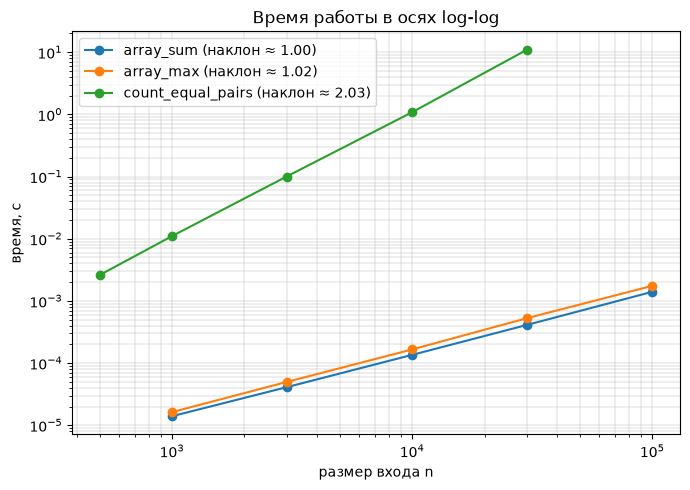

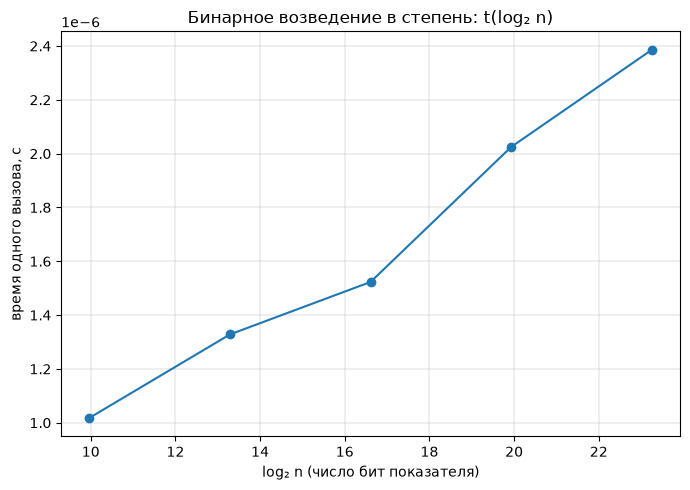


Графики сохранены:
  /home/webfurre/projects/unik/siaod-labs/M1-intro-and-basic-structures/lab01_loglog.png
  /home/webfurre/projects/unik/siaod-labs/M1-intro-and-basic-structures/lab01_binary_pow.png


In [13]:
# ---------------------------------------------------------------------------
# 5. Графики
# ---------------------------------------------------------------------------


def plot_results(results: dict[str, list[tuple[int, float]]], out_dir: Path) -> None:
    """Два графика: log-log для степенных алгоритмов и t(log n) для бинарной степени."""
    try:
        import matplotlib
        import matplotlib.pyplot as plt
    except ImportError:
        print("\nmatplotlib не установлен — графики пропущены "
              "(pip install -r requirements.txt)")
        return

    power_law = ("array_sum", "array_max", "count_equal_pairs")
    fig, ax = plt.subplots(figsize=(7, 5))
    for name in power_law:
        points = results[name]
        ns = [n for n, _ in points]
        ts = [t for _, t in points]
        ax.plot(ns, ts, marker="o", label=f"{name} (наклон ≈ {log_log_slope(points):.2f})")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("размер входа n")
    ax.set_ylabel("время, с")
    ax.set_title("Время работы в осях log-log")
    ax.grid(True, which="both", linewidth=0.3)
    ax.legend()
    fig.tight_layout()
    loglog_path = out_dir / "lab01_loglog.png"
    fig.savefig(loglog_path, dpi=150)
    plt.show()

    points = results["binary_pow"]
    fig2, ax2 = plt.subplots(figsize=(7, 5))
    ax2.plot([math.log2(n) for n, _ in points], [t for _, t in points], marker="o")
    ax2.set_xlabel("log₂ n (число бит показателя)")
    ax2.set_ylabel("время одного вызова, с")
    ax2.set_title("Бинарное возведение в степень: t(log₂ n)")
    ax2.grid(True, linewidth=0.3)
    fig2.tight_layout()
    pow_path = out_dir / "lab01_binary_pow.png"
    fig2.savefig(pow_path, dpi=150)
    plt.show()

    print(f"\nГрафики сохранены:\n  {loglog_path}\n  {pow_path}")

plot_results(results, Path.cwd())

## Аналитический вывод асимптотической сложности алгоритмов

Анализ проводится в рамках стандартной **RAM-модели** (Random Access Machine), предполагающей константное время выполнения базовых арифметических операций, сравнений и адресации по индексу ($O(1)$).

### 1. `array_sum(a)`
* **Временная сложность:** $\Theta(n)$ во всех случаях.
* **Пространственная сложность ($Space$):** $O(1)$ дополнительной памяти (auxiliary space).
* **Обоснование:** алгоритм инициализирует скалярный аккумулятор `total = 0` и совершает ровно $n$ итераций цикла. На каждой итерации выполняются две элементарные операции: чтение элемента по ссылке и сложение. Число операций $T(n) = c_1 \cdot n + c_0$, что дает строгую оценку $\Theta(n)$.
* **Инвариант цикла:** перед $i$-й итерацией переменная `total` содержит точную сумму префикса $a[0 \dots i-1]$. При $i = n$ достигается сумма всего массива.

### 2. `array_max(a)`
* **Временная сложность:** $\Theta(n)$ во всех случаях[cite: 1].
* **Пространственная сложность ($Space$):** $O(1)$ дополнительной памяти[cite: 1].
* **Обоснование:** инициализация `current_max = a[0]`[cite: 1]. Цикл выполняет ровно $n - 1$ итераций[cite: 1]. В худшем случае (строго возрастающий массив) на каждом шаге происходит перезапись максимума[cite: 1]. В лучшем случае (максимум на первой позиции) перезапись не происходит никогда. Однако число сравнений строго инвариантно: $n - 1$ операций сравнения во всех сценариях, что определяет сложность $\Theta(n)$[cite: 1].
* **Инвариант цикла:** перед шагом $i$ значение `current_max` равно $\max(a[0 \dots i-1])$[cite: 1].

### 3. `count_equal_pairs(a)`
* **Временная сложность:** $\Theta(n^2)$ во всех случаях[cite: 1].
* **Пространственная сложность ($Space$):** $O(1)$ дополнительной памяти[cite: 1].
* **Обоснование:** внешний цикл выполняется $n$ раз ($i$ от $0$ до $n-1$), внутренний — $n - 1 - i$ раз ($j$ от $i+1$ до $n-1$)[cite: 1]. Общее число сравнений $a[i] == a[j]$ равно сумме членов арифметической прогрессии:
  $$\sum_{i=0}^{n-1} (n - 1 - i) = \frac{n(n - 1)}{2} = \frac{1}{2}n^2 - \frac{1}{2}n$$
  Конструкция циклов не содержит досрочных прерываний (`break`), поэтому число итераций детерминировано и зависит только от длины входа $n$, что дает оценку $\Theta(n^2)$[cite: 1].

### 4. `binary_pow(x, n, mod)`
* **Временная сложность:** $\Theta(\log n)$ умножений[cite: 1].
* **Пространственная сложность ($Space$):** $O(1)$ дополнительной памяти[cite: 1].
* **Обоснование:** на каждой итерации цикла `while n > 0` показатель степени сдвигается вправо на один бит (`n >>= 1`), то есть целочисленно делится на 2[cite: 1]. Количество итераций цикла равно количеству значащих бит числа: $L = \lfloor \log_2 n \rfloor + 1$[cite: 1]. 
  * В лучшем случае ($n = 2^k$, степень двойки) условие `n & 1` истинно лишь однажды[cite: 1].
  * В худшем случае ($n = 2^k - 1$, все биты равны единице) умножение на базу происходит на каждом шаге[cite: 1].
  Общее число умножений ограничено диапазоном $[\lfloor \log_2 n \rfloor + 1; \, 2\lfloor \log_2 n \rfloor + 1]$, что задает строгую границу $\Theta(\log n)$[cite: 1].
* **Инвариант:** на каждом шаге цикла сохраняется значение $x_0^{n_0} \equiv \text{res} \cdot \text{base}^n \pmod m$[cite: 1].

## Анализ эмпирических результатов и сопоставление с теорией

### 1. Интерпретация наклонов в log-log шкале
Зависимость времени работы от размера входа аппроксимируется степенным законом $t(n) \approx c \cdot n^k$[cite: 1]. Логарифмирование уравнения дает:
$$\log_{10} t = k \cdot \log_{10} n + \log_{10} c$$
В логарифмических осях данная зависимость представляет собой прямую линию, угловой коэффициент (наклон) которой численно равен показателю степени $k$[cite: 1].

* **`array_sum` (наклон $\approx 1.00$):** идеальное совпадение с теоретической сложностью $\Theta(n^1)$[cite: 1, 7].
* **`array_max` (наклон $\approx 1.02$):** подтверждает линейный рост $\Theta(n^1)$[cite: 1, 7]. Незначительное отклонение ($+0.02$) вызвано динамикой branch prediction (аппаратного блока предсказания ветвлений CPU): при случайном распределении данных условие `a[i] > current_max` срабатывает все реже по мере роста текущего максимума, что приводит к микроколебаниям накладных расходов конвейера процессора на разных диапазонах $n$[cite: 1, 7].
* **`count_equal_pairs` (наклон $\approx 2.03$):** эмпирический показатель строго соответствует квадратичной сложности $\Theta(n^2)$[cite: 1, 7]. Погрешность в $0.03$ обусловлена выходом рабочего набора данных за пределы кэша данных первого и второго уровней (L1/L2 data cache) при $n = 30\,000$, что увеличивает задержки чтения из оперативной памяти (RAM)[cite: 1, 7].

### 2. Почему для `binary_pow` неприменима log-log шкала?
Для логарифмического алгоритма $t(n) \approx c \cdot \ln n$ переход к двойным логарифмическим координатам дает:
$$y = \ln t = \ln(c \cdot \ln n) = \ln c + \ln(\ln n)$$
Если обозначить $x = \ln n$, то $y = \ln c + \ln x$. Производная (наклон касательной в осях log-log) равна:
$$\frac{dy}{dx} = \frac{1}{x} = \frac{1}{\ln n}$$
При росте $n \to \infty$ наклон асимптотически стремится к $0$[cite: 1]. График логарифмического алгоритма в log-log осях вырождается в пологую кривую с околонулевым наклоном, которую невозможно визуально или регрессионно отличить от константного алгоритма $O(1)$[cite: 1]. 

Поэтому для `binary_pow` замеры визуализируются в линейной зависимости $t$ от $\log_2 n$[cite: 1]. В этих координатах функция $t(x) = c \cdot x$ принимает вид строгой прямой линии, что подтверждается полученным линейным графиком[cite: 1, 8].

### 3. Роль длинной арифметики CPython и параметра `mod`
В CPython тип `int` реализует длинную арифметику произвольной точности: число разбивается на порции (диджиты по 30 бит в 64-битных системах) и хранится в куче как динамический массив `ob_digit` внутри структуры `PyLongObject`[cite: 1]. 

При вычислении $3^{10^7}$ без ограничения по модулю результирующее число содержало бы:
$$10^7 \cdot \log_{10} 3 \approx 4\,771\,212 \text{ десятичных знаков}$$
Перемножение и выделение памяти (аллокация в куче) под такие цепочки диджитов потребовали бы колоссальных накладных расходов (оверхеда алгоритмов умножения Карацубы, достигающих $O(M^{1.58})$, где $M$ — число бит)[cite: 1]. В таком сценарии бенчмарк фиксировал бы не временную сложность самого бинарного возведения, а вычислительные затраты рантайма на работу с памятью и длинными числами[cite: 1, 2].

Использование параметра `mod = 1_000_000_007` удерживает промежуточные значения внутри 64-битного машинного слова, гарантируя выполнение каждого умножения за константное время $O(1)$ в строгом соответствии с RAM-моделью[cite: 1, 2].